# Kredi Geri Ödeme Tahmini: İyi Müşteriyi Belirleme

**İş hedefi:** Bir finans kurumu, krediyi geri ödememe (default) ihtimali düşük olan müşterileri belirlemek istiyor. Bizden iki şey isteniyor:
1. Kimin iyi müşteri olduğunu tahmin eden bir model geliştirmek.
2. Modele dayanarak, müşteri kredi başvurusu yaparken ona sorulacak soruları belirlemek.

Veri seti gerçek hayattaki verilerin sorunlarını içeriyor: boş değerler, yazım farklılıkları, noktalama farklılıkları ve tekrar eden satırlar. Önce bu sorunları bulup temizleyeceğiz, sonra ödevin istediği 4 algoritma türünden 5 model kuracağız:
- **Regresyon tabanlı:** Logistic Regression
- **Ağaç tabanlı:** Decision Tree ve Random Forest
- **Mesafe tabanlı:** KNN
- **Olasılık tabanlı:** Gaussian Naive Bayes

Hedefimiz accuracy > 0.80. Veri seti: LoansTrainingSet.csv (256.984 satır, 19 sütun) ve veri sözlüğü.

Data Dictionary:
- Loan ID, Customer ID: kredi ve müşteri numarası
- **Loan Status:** kredi ödendi mi (Fully Paid) yoksa batık mı (Charged Off) - hedef değişken
- Current Loan Amount: kredi tutarı
- Term: kısa vadeli (Short Term) veya uzun vadeli (Long Term)
- Credit Score: 0-800 arası kredi notu
- Years in current job: mevcut işteki yıl
- Home Ownership: kira (Rent), ipotekli ev (Home Mortgage), kendi evi (Own Home)
- Annual Income: yıllık gelir
- Purpose: kredinin amacı
- Monthly Debt: mevcut kredilerin aylık ödemesi
- Years of Credit History: kredi geçmişinin yılı
- Months since last delinquent: son geç ödemeden bu yana geçen ay
- Number of Open Accounts: açık kredi kartı sayısı
- Number of Credit Problems: kredi sorunu sayısı
- Current Credit Balance: mevcut toplam borç
- Maximum Open Credit: bütün kredilerin toplam limiti
- Bankruptcies: iflas sayısı
- Tax Liens: vergi haczi sayısı

**Ne yapıyoruz:** Kullanacağımız kütüphaneleri yüklüyoruz.

In [1]:
import pandas as pd # tablo işlemleri
import numpy as np # matematik paketi
import matplotlib.pyplot as plt # grafik çizimi
import seaborn as sns # istatistiksel grafikler

In [2]:
df=pd.read_csv('LoansTrainingSet.csv', low_memory=False) # veriyi oku, büyük dosyada sütun tiplerini doğru belirlemek için low_memory=False

## 1. Keşifçi Veri Analizi (EDA) ve Veri Sorunlarının Bulunması

In [3]:
df.head() # ilk 5 satır

,Loan ID,Customer ID,Loan Status,Current Loan Amount,Term,Credit Score,Years in current job,Home Ownership,Annual Income,Purpose,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens
0,000025bb-5694-4cff-b17d-192b1a98ba44,5ebc8bb1-5eb9-4404-b11b-a6eebc401a19,Fully Paid,11520,Short Term,741.0,10+ years,Home Mortgage,33694.0,Debt Consolidation,$584.03,12.3,41.0,10,0,6760,16056,0.0,0.0
1,00002c49-3a29-4bd4-8f67-c8f8fbc1048c,927b388d-2e01-423f-a8dc-f7e42d668f46,Fully Paid,3441,Short Term,734.0,4 years,Home Mortgage,42269.0,other,"$1,106.04",26.3,NaN,17,0,6262,19149,0.0,0.0
2,00002d89-27f3-409b-aa76-90834f359a65,defce609-c631-447d-aad6-1270615e89c4,Fully Paid,21029,Short Term,747.0,10+ years,Home Mortgage,90126.0,Debt Consolidation,"$1,321.85",28.8,NaN,5,0,20967,28335,0.0,0.0
3,00005222-b4d8-45a4-ad8c-186057e24233,070bcecb-aae7-4485-a26a-e0403e7bb6c5,Fully Paid,18743,Short Term,747.0,10+ years,Own Home,38072.0,Debt Consolidation,$751.92,26.2,NaN,9,0,22529,43915,0.0,0.0
4,0000757f-a121-41ed-b17b-162e76647c1f,dde79588-12f0-4811-bab0-e2b07f633fcd,Fully Paid,11731,Short Term,746.0,4 years,Rent,50025.0,Debt Consolidation,$355.18,11.5,NaN,12,0,17391,37081,0.0,0.0


In [4]:
df.shape # satır ve sütun sayısı

(256984, 19)

In [5]:
df.info() # sütunların veri tipleri

<class 'pandas.DataFrame'>
RangeIndex: 256984 entries, 0 to 256983
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Loan ID                       256984 non-null  str    
 1   Customer ID                   256984 non-null  str    
 2   Loan Status                   256984 non-null  str    
 3   Current Loan Amount           256984 non-null  int64  
 4   Term                          256984 non-null  str    
 5   Credit Score                  195308 non-null  float64
 6   Years in current job          245508 non-null  str    
 7   Home Ownership                256984 non-null  str    
 8   Annual Income                 195308 non-null  float64
 9   Purpose                       256984 non-null  str    
 10  Monthly Debt                  256984 non-null  str    
 11  Years of Credit History       256984 non-null  float64
 12  Months since last delinquent  116601 non-null  float64


**Sonuç:** 256.984 satır ve 19 sütun var. Monthly Debt ve Maximum Open Credit sütunları sayı olması gerekirken metin (str) olarak okunmuş; bu sütunlarda sayı olmayan karakterler var.

In [6]:
df['Loan Status'].value_counts() # hedef değişken

Loan Status
Fully Paid     176191
Charged Off     80793
Name: count, dtype: int64

### Sorun 1: Tekrar eden satırlar

In [7]:
df.duplicated().sum() # birebir tekrar eden satır sayısı

np.int64(16611)

In [8]:
df['Loan ID'].duplicated().sum() # numarası tekrar eden kredi sayısı

np.int64(41284)

**Sonuç:** 16.611 satır birebir tekrar ediyor. Ayrıca kredi numarası 41.284 kez tekrar ediyor; yani bazı krediler birebir aynı olmayan satırlarla birden fazla kez kaydedilmiş. Bunlardan bir örneğe bakıyoruz.

In [9]:
df[df['Loan ID']=='0000afa6-8902-4f8f-b870-25a8fdad0aeb'][['Loan ID','Loan Status','Current Loan Amount','Credit Score','Annual Income']] # aynı kredinin iki satırı

,Loan ID,Loan Status,Current Loan Amount,Credit Score,Annual Income
6,0000afa6-8902-4f8f-b870-25a8fdad0aeb,Charged Off,24613,6640.0,49225.0
7,0000afa6-8902-4f8f-b870-25a8fdad0aeb,Charged Off,24613,NaN,NaN


**Sonuç:** Aynı kredi iki kez kaydedilmiş: bir satırda kredi notu ve gelir dolu, diğerinde boş. Her krediyi tek bir satırda toplayıp dolu olan değerleri almamız gerekiyor.

### Sorun 2: Yazım farklılıkları

In [10]:
df['Purpose'].value_counts() # kredinin amacı

Purpose
Debt Consolidation      203911
Home Improvements        14915
other                    14268
Other                     9667
Business Loan             4712
Buy a Car                 3276
Medical Bills             2868
Take a Trip               1570
Buy House                 1530
Educational Expenses       267
Name: count, dtype: int64

In [11]:
df['Home Ownership'].value_counts() # ev sahipliği

Home Ownership
Home Mortgage    124477
Rent             109010
Own Home          22923
HaveMortgage        574
Name: count, dtype: int64

**Sonuç:** Aynı şey farklı yazılmış: Purpose'ta 'other' ve 'Other'; Home Ownership'te 'HaveMortgage' ve 'Home Mortgage'. Veri sözlüğüne göre Home Ownership sadece 'Rent', 'Home Mortgage' ve 'Own' değerlerini alıyor; 'HaveMortgage', 'Home Mortgage' ile aynı anlama geliyor.

### Sorun 3: Noktalama ve format farklılıkları

In [12]:
df['Monthly Debt'].head(10) # aylık borç ödemesi

0       $584.03
1    $1,106.04 
2    $1,321.85 
3       $751.92
4       $355.18
5       $561.52
6       $542.29
7       $542.29
8       $386.36
9       $741.79
Name: Monthly Debt, dtype: str

In [13]:
df[df['Maximum Open Credit']=='#VALUE!'].shape[0] # Excel hata değeri olan satır sayısı

4

**Sonuç:** Monthly Debt '$1,106.04' gibi dolar işareti, binlik virgülü ve bazen sonda boşlukla yazılmış; bu yüzden metin olarak okunmuş. Maximum Open Credit sütununda 4 satırda Excel'den kalan '#VALUE!' hata değeri var.

### Sorun 4: Boş değerler

In [14]:
df.isnull().sum() # hangi sütunda kaç boş değer var

Loan ID                              0
Customer ID                          0
Loan Status                          0
Current Loan Amount                  0
Term                                 0
Credit Score                     61676
Years in current job             11476
Home Ownership                       0
Annual Income                    61676
Purpose                              0
Monthly Debt                         0
Years of Credit History              0
Months since last delinquent    140383
Number of Open Accounts              0
Number of Credit Problems            0
Current Credit Balance               0
Maximum Open Credit                  0
Bankruptcies                       529
Tax Liens                           23
dtype: int64

**Sonuç:** Credit Score ve Annual Income 61.676 satırda boş. Months since last delinquent sütununun yarıdan fazlası (140.383) boş: müşterinin hiç geç ödemesi yoksa bu alan boş kalıyor. Years in current job, Bankruptcies ve Tax Liens'te de boş değerler var.

### Sorun 5: Mantıksız değerler

In [15]:
df['Credit Score'].describe() # kredi notu

count    195308.000000
mean       1251.116099
std        1762.016848
min         585.000000
25%         714.000000
50%         733.000000
75%         744.000000
max        7510.000000
Name: Credit Score, dtype: float64

In [16]:
df[df['Credit Score']>800]['Credit Score'].head() # 800'ün üzerindeki kredi notları

6     6640.0
55    7320.0
71    7180.0
73    6670.0
79    7270.0
Name: Credit Score, dtype: float64

**Sonuç:** Veri sözlüğüne göre kredi notu en fazla 800, ama 16.187 satırda 5.850 ile 7.510 arasında. Bunlar sonuna fazladan 0 eklenmiş notlar: 6640 aslında 664.

In [17]:
(df['Current Loan Amount']==99999999).sum() # kredi tutarı 99.999.999 olan satır sayısı

np.int64(35210)

**Sonuç:** 35.210 satırda kredi tutarı 99.999.999; bu gerçek bir tutar değil, 'bilinmiyor' anlamında girilmiş bir değer.

### Bu hataların hedefle ilişkisi

**Ne yapıyoruz:** Mantıksız değerlerin kredinin ödenip ödenmemesiyle ilişkisine bakıyoruz. Derslerdeki `np.where` ile her satırın batık olup olmadığını 1 ve 0 olarak işaretliyoruz; batık kredi oranı bu sütunun ortalaması.

In [18]:
df['batik']=np.where(df['Loan Status']=='Charged Off', 1, 0) # batık kredi 1, ödenmiş 0
df.groupby(df['Credit Score']>800)['batik'].mean() # kredi notu 800 üzerindeyse batık oranı

Credit Score
False    0.268301
True     1.000000
Name: batik, dtype: float64

In [19]:
df.groupby(df['Current Loan Amount']==99999999)['batik'].mean() # kredi tutarı 99.999.999 ise batık oranı

Current Loan Amount
False    0.364303
True     0.000000
Name: batik, dtype: float64

**Sonuç:** Bu sonuç çok önemli. Kredi notu 800'ün üzerinde yazılmış kredilerin **%100'ü batık**, kredi tutarı 99.999.999 yazılmış kredilerin **%100'ü ödenmiş**. Gerçek hayatta bir müşterinin kredi notunun yanlış yazılması, onun krediyi ödeyip ödemeyeceğini belirlemez. Bu desenler verinin hazırlanma şeklinden kaynaklanan hatalar.

Bu hatalar olduğu gibi bırakılırsa model, kredi riskini öğrenmek yerine 'not 800'den büyükse batık, tutar 99.999.999 ise ödenmiş' kuralını ezberler. Bu kurallar test verisinde de geçerli olduğu için model çok başarılı görünür, ama gerçek bir başvuruda bu hatalar olmayacağı için işe yaramaz. Bu bir **veri sızıntısıdır**. Bu yüzden:
- Kredi notlarını 10'a bölerek düzelteceğiz.
- Kredi tutarı bilinmeyen 35.210 krediyi veriden çıkaracağız; tutarı bilinmeyen bir kredi için doğru bir risk değerlendirmesi yapılamaz.

## 2. Veri Temizleme

**Ne yapıyoruz:** Kredi tutarı 99.999.999 olan değerleri önce boş değere (NaN) çeviriyoruz. Sonra tekrar eden kredileri birleştirmek için derslerdeki `groupby` ile her kredi numarasını tek satırda topluyor ve `max()` alıyoruz: `max()` boş değerleri atlayıp her sütunda dolu olan değeri seçiyor. Böylece hem birebir tekrarlar hem de bir satırı eksik olan tekrarlar tek satıra iniyor. 99.999.999'u önce boş yapmamızın sebebi, `max()`'ın gerçek tutar yerine bu sahte değeri seçmesini önlemek.

In [20]:
df['Current Loan Amount']=df['Current Loan Amount'].replace(99999999, np.nan) # bilinmeyen tutarı boş değer yap
df=df.groupby('Loan ID').max().reset_index() # her krediyi tek satırda topla, dolu değerleri al
df.shape # tekil kredi sayısı

(215700, 20)

In [21]:
df['Loan ID'].duplicated().sum() # kalan tekrar sayısı

np.int64(0)

**Sonuç:** 256.984 satır 215.700 tekil krediye indi; tekrar kalmadı.

In [22]:
df=df[df['Current Loan Amount'].notnull()] # tutarı bilinmeyen kredileri çıkar
df['Credit Score']=np.where(df['Credit Score']>800, df['Credit Score']/10, df['Credit Score']) # fazladan 0 eklenmiş notları düzelt
df.shape, df['Credit Score'].max() # kalan kredi sayısı ve en yüksek kredi notu

((180490, 20), np.float64(751.0))

**Sonuç:** Kredi tutarı bilinen 180.490 kredi kaldı ve en yüksek kredi notu artık 751.

In [23]:
df['Purpose']=df['Purpose'].replace('other','Other') # yazım farkını düzelt
df['Home Ownership']=df['Home Ownership'].replace('HaveMortgage','Home Mortgage') # aynı anlam, tek yazım
df['Monthly Debt']=df['Monthly Debt'].str.replace('$','', regex=False).str.replace(',','', regex=False).astype(float) # $ ve virgülü kaldır, sayıya çevir
df['Maximum Open Credit']=df['Maximum Open Credit'].replace('#VALUE!', np.nan).astype(float) # Excel hatasını boş değer yap, sayıya çevir

**Ne yapıyoruz:** Years in current job sütunu '10+ years', '< 1 year' gibi metinler içeriyor. Derslerdeki `str.replace` ile bu metinleri yıl sayısına çeviriyoruz: '< 1 year' 0, '10+ years' 10 yıl.

In [24]:
df['is_yili']=df['Years in current job'].str.replace('< 1 year','0', regex=False).str.replace('10+ years','10', regex=False).str.replace(' years','', regex=False).str.replace(' year','', regex=False).astype(float) # yıl sayısı
df['is_yili'].value_counts().sort_index() # yıllara göre müşteri sayısı

is_yili
0.0     14787
1.0     11824
2.0     16593
3.0     14601
4.0     11383
5.0     12583
6.0     10206
7.0      9812
8.0      8563
9.0      6953
10.0    55570
Name: count, dtype: int64

### Temizlenmiş veriyle EDA

In [25]:
df.groupby('Term')['batik'].mean() # vadeye göre batık oranı

Term
Long Term     0.344854
Short Term    0.180445
Name: batik, dtype: float64

In [26]:
df.groupby('Home Ownership')['batik'].mean() # ev sahipliğine göre batık oranı

Home Ownership
Home Mortgage    0.194202
Own Home         0.227287
Rent             0.246164
Name: batik, dtype: float64

In [27]:
df.groupby('Purpose')['batik'].mean().sort_values() # amaca göre batık oranı

Purpose
Buy a Car               0.143747
Home Improvements       0.186610
Buy House               0.206992
Take a Trip             0.215580
Debt Consolidation      0.219181
Educational Expenses    0.219780
Other                   0.224253
Medical Bills           0.236382
Business Loan           0.339629
Name: batik, dtype: float64

**Sonuç:** Uzun vadeli kredilerin %34,5'i, kısa vadelilerin %18'i batık; uzun vade riski neredeyse iki katına çıkarıyor. Kirada oturanlarda batık oranı %24,6, ipotekli ev sahiplerinde %19,4. Amaca göre en riskli kredi iş kredisi (%34), en güvenlisi araba kredisi (%14).

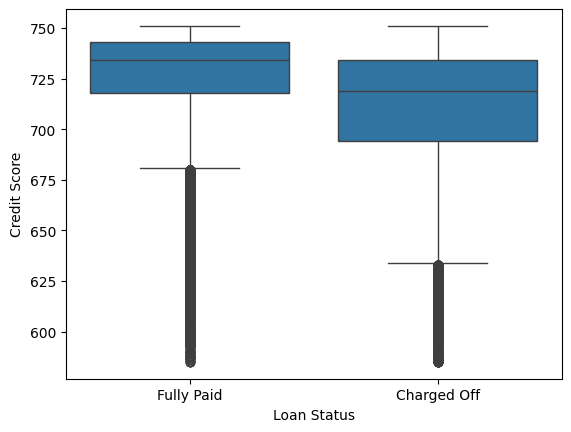

In [28]:
sns.boxplot(x=df['Loan Status'], y=df['Credit Score']); # kredi notu ve kredi durumu

In [29]:
df.groupby('Loan Status')[['Credit Score','Annual Income','Current Loan Amount','Monthly Debt']].median() # iki grubun ortanca değerleri

,Credit Score,Annual Income,Current Loan Amount,Monthly Debt
Loan Status,,,,
Charged Off,719.0,56575.5,13018.0,863.76
Fully Paid,734.0,64183.5,11838.0,834.36


**Sonuç:** Batık kredilerde ortanca kredi notu 719, ödenen kredilerde 734. Batık kredi alanların ortanca geliri daha düşük (56.576'ya karşı 64.184), kredi tutarı ise daha yüksek (13.018'e karşı 11.838). Farklar var, ama küçük: iki grup birbirine çok benziyor. Bu da kredinin batıp batmayacağını tahmin etmenin zor olacağını gösteriyor.

In [30]:
df.groupby(df['Credit Score'].isnull())['batik'].mean() # kredi notu boşsa batık oranı

Credit Score
False    0.273693
True     0.051441
Name: batik, dtype: float64

**Sonuç:** Kredi notu boş olan kredilerin sadece %5,1'i batık, notu bilinenlerde bu oran %27,4. Bu çok büyük ve şüpheli bir fark.

**Ne yapıyoruz:** Kredi notu boş olan krediler de veriden çıkarılmalı. Bu kararın gerekçesi:
- Kredi notu boş olan kredilerin sadece %5'i batık; notu bilinenlerde bu oran %27. Kredi notunun bilinmemesi gerçek hayatta bir müşteriyi daha güvenilir yapmaz; bu da verinin hazırlanma şeklinden kaynaklanan bir desen.
- Bu satırlarda yıllık gelir de boş; yani en önemli iki bilgi eksik.
- Gerçek bir kredi başvurusunda banka müşterinin kredi notunu her zaman sorgular; notu bilinmeyen bir başvuru olmaz.
- Bu satırlar kalırsa ve boş notlar ortanca değerle doldurulursa, ağaç modelleri 'notu tam ortanca değer olan müşteri iyidir' kuralını ezberler. Bu, yukarıdaki iki veri hatası gibi bir veri sızıntısı olur. (Bu notebook'un ilk denemesinde bunu kontrol ettik: Random Forest'ın en güvenli bulduğu %10'luk grubun %87'si kredi notu boş olan müşterilerdi.)

In [31]:
df=df[df['Credit Score'].notnull()] # kredi notu bilinen krediler
df.shape # kalan kredi sayısı

(135992, 21)

In [32]:
df['batik'].mean() # temizlenmiş veride batık kredi oranı

np.float64(0.27369257015118537)

**Sonuç:** Kredi notu bilinen 135.992 kredi kaldı ve bunların %27,4'ü batık. Herkese 'krediyi öder' diyen bir model bile yaklaşık %73 accuracy alır; bu, modellerimizi karşılaştıracağımız başlangıç noktası.

## 3. Eğitim ve Test Verisi

**Ne yapıyoruz:** Boş değerleri doldurmadan önce veriyi bölüyoruz; böylece doldurma değerlerini sadece eğitim verisinden hesaplayabiliyoruz. Model için kullanılmayacak sütunları (kredi ve müşteri numaraları, metin hali olan iş yılı ve hedefin kopyaları) çıkarıyoruz. Hedef: kredi ödendiyse 1 (iyi müşteri), batıksa 0.

In [33]:
x=df.drop(['Loan ID','Customer ID','Loan Status','Years in current job','batik'], axis=1) # özellikler
y=np.where(df['Loan Status']=='Fully Paid', 1, 0) # iyi müşteri 1, batık 0
from sklearn.model_selection import train_test_split # veriyi bölme
x_train, x_test, y_train, y_test=train_test_split(x,y, test_size=0.20, random_state=42) # %80 eğitim %20 test
x_train.shape, x_test.shape # eğitim ve test boyutu

((108793, 16), (27199, 16))

### Boş değerleri doldurma

**Ne yapıyoruz:** Kalan boş değerleri eğitim verisinin ortancasıyla (median) dolduruyoruz. Gelir ve borç gibi sütunlarda birkaç çok büyük değer ortalamayı yukarı çektiği için ortalama yerine ortanca kullanıyoruz. Months since last delinquent boşsa müşterinin hiç geç ödemesi yok demek; bu yüzden bu sütunu, en uzun süreden de büyük bir değerle (200 ay) dolduruyoruz.

In [34]:
for sutun in ['Credit Score','Annual Income','is_yili','Bankruptcies','Tax Liens','Maximum Open Credit']: # boş değeri olan sütunlar
    ortanca=x_train[sutun].median() # eğitim verisinin ortancası
    x_train[sutun]=x_train[sutun].fillna(ortanca) # eğitim verisini doldur
    x_test[sutun]=x_test[sutun].fillna(ortanca) # test verisini aynı değerle doldur
x_train['Months since last delinquent']=x_train['Months since last delinquent'].fillna(200) # hiç geç ödemesi yok
x_test['Months since last delinquent']=x_test['Months since last delinquent'].fillna(200) # hiç geç ödemesi yok
x_train.isnull().sum().sum(), x_test.isnull().sum().sum() # kalan boş değer

(np.int64(0), np.int64(0))

## 4. Feature Engineering

**Ne yapıyoruz:** Ödevde örnek olarak verilen kredi kullanım oranı gibi, bankaların risk değerlendirmesinde kullandığı oranları hesaplıyoruz:
- **kredi_kullanim (credit utilization):** mevcut borç / toplam kredi limiti. Limitinin çoğunu kullanan müşteri daha riskli.
- **borc_gelir (debt-to-income):** yıllık borç ödemesi / yıllık gelir.
- **kredi_gelir:** istenen kredi tutarı / yıllık gelir.

Paydanın 0 olduğu satırlarda bölme hatası olmaması için paydaya 1 ekliyoruz.

In [35]:
for t in [x_train, x_test]: # eğitim ve test verisi
    t['kredi_kullanim']=t['Current Credit Balance']/(t['Maximum Open Credit']+1) # kredi kullanım oranı
    t['borc_gelir']=t['Monthly Debt']*12/(t['Annual Income']+1) # borç-gelir oranı
    t['kredi_gelir']=t['Current Loan Amount']/(t['Annual Income']+1) # kredi-gelir oranı
x_train[['kredi_kullanim','borc_gelir','kredi_gelir']].describe() # yeni sütunların istatistikleri

,kredi_kullanim,borc_gelir,kredi_gelir
count,108793.000000,108793.000000,108793.000000
mean,30.593561,0.170587,0.248136
std,1497.575431,0.079533,10.981065
min,0.000000,0.000000,0.000919
25%,0.370958,0.110999,0.127271
50%,0.562007,0.166998,0.199998
75%,0.741944,0.225997,0.291992
max,158645.000000,0.399996,3622.000000


### Kategorik verileri sayıya çevirme

In [36]:
x_train=pd.get_dummies(x_train, drop_first=True) # metin sütunlarını 0-1 sütunlara çevir
x_test=pd.get_dummies(x_test, drop_first=True) # test verisi
x_train.shape, x_test.shape # sütun sayıları aynı olmalı

((108793, 27), (27199, 27))

**Ne yapıyoruz:** Logistic Regression, KNN ve Gaussian NB sayıların büyüklüğüne duyarlı olduğu için derslerdeki StandardScaler'ı sadece eğitim verisiyle öğretiyoruz. Ağaç modelleri ölçeklendirme gerektirmiyor.

In [37]:
from sklearn.preprocessing import StandardScaler # ölçeklendirme
sc=StandardScaler() # scaler
x_train_sc=sc.fit_transform(x_train) # eğitim verisiyle öğren ve dönüştür
x_test_sc=sc.transform(x_test) # test verisini aynı kuralla dönüştür

## 5. Modelleme

In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report # başarı ölçüleri
tahminler={} # modellerin tahminleri
olasiliklar={} # modellerin iyi müşteri olasılıkları

### 1. Regresyon tabanlı: Logistic Regression

In [39]:
from sklearn.linear_model import LogisticRegression # lojistik regresyon
L=LogisticRegression(max_iter=1000) # modeli oluştur
L.fit(x_train_sc,y_train) # eğit
tahminler['LogisticRegression']=L.predict(x_test_sc) # tahmin
olasiliklar['LogisticRegression']=L.predict_proba(x_test_sc)[:,1] # iyi müşteri olma olasılığı
accuracy_score(y_test,tahminler['LogisticRegression']) # doğruluk oranı

0.7395860141916982

### 2. Ağaç tabanlı: Decision Tree

**Ne yapıyoruz:** Sınırsız büyüyen bir karar ağacı 144 bin eğitim kredisini ezberler. Ağacın derinliğini 8 ile sınırlıyoruz (`max_depth`).

In [40]:
from sklearn.tree import DecisionTreeClassifier # karar ağacı
dt=DecisionTreeClassifier(max_depth=8, random_state=42) # en fazla 8 seviye
dt.fit(x_train,y_train) # eğit
tahminler['DecisionTree']=dt.predict(x_test) # tahmin
olasiliklar['DecisionTree']=dt.predict_proba(x_test)[:,1] # iyi müşteri olasılığı
accuracy_score(y_test,tahminler['DecisionTree']) # doğruluk oranı

0.7346961285341372

### 3. Ağaç tabanlı: Random Forest

In [41]:
from sklearn.ensemble import RandomForestClassifier # rastgele orman
rf=RandomForestClassifier(random_state=42, n_jobs=-1) # 100 ağaç, bütün işlemciler
rf.fit(x_train,y_train) # eğit
tahminler['RandomForest']=rf.predict(x_test) # tahmin
olasiliklar['RandomForest']=rf.predict_proba(x_test)[:,1] # iyi müşteri olasılığı
accuracy_score(y_test,tahminler['RandomForest']) # doğruluk oranı

0.7380050737159455

### 4. Mesafe tabanlı: KNN

**Ne yapıyoruz:** KNN her test kredisi için eğitim verisindeki en benzer 5 krediye bakıyor. 36 bin test kredisinin her birini 144 bin eğitim kredisiyle karşılaştırmak uzun sürdüğü için bu hücre birkaç dakika sürebilir.

In [42]:
from sklearn.neighbors import KNeighborsClassifier # en yakın komşu
k=KNeighborsClassifier(n_jobs=-1) # 5 komşu, bütün işlemciler
k.fit(x_train_sc,y_train) # eğit
tahminler['KNN']=k.predict(x_test_sc) # tahmin
olasiliklar['KNN']=k.predict_proba(x_test_sc)[:,1] # iyi müşteri olasılığı
accuracy_score(y_test,tahminler['KNN']) # doğruluk oranı

0.7023419978675687

### 5. Olasılık tabanlı: Gaussian Naive Bayes

In [43]:
from sklearn.naive_bayes import GaussianNB # Gaussian Naive Bayes
g=GaussianNB() # modeli oluştur
g.fit(x_train_sc,y_train) # eğit
tahminler['GaussianNB']=g.predict(x_test_sc) # tahmin
olasiliklar['GaussianNB']=g.predict_proba(x_test_sc)[:,1] # iyi müşteri olasılığı
accuracy_score(y_test,tahminler['GaussianNB']) # doğruluk oranı

0.7330048898856576

## 6. Model Değerlendirme

**Ne yapıyoruz:** Banka için iki hata türünün maliyeti farklı. Batık olacak bir müşteriye 'iyi müşteri' demek bankaya kredinin tamamını kaybettirir; iyi bir müşteriyi reddetmek ise sadece kazanılacak faizi kaybettirir. Bu yüzden accuracy'nin yanında şunlara bakıyoruz:
- **Precision (iyi müşteri):** Model 'iyi müşteri' dediklerinin yüzde kaçı gerçekten krediyi ödedi?
- **Batık yakalama (recall, batık):** Batık kredilerin yüzde kaçını model önceden fark etti?

In [44]:
sonuc=pd.DataFrame(columns=['Accuracy','Precision_iyi','Recall_iyi','Batik_yakalama'], index=tahminler.keys()) # sonuç tablosu
for isim,p in tahminler.items(): # her model
    sonuc.loc[isim,'Accuracy']=accuracy_score(y_test,p) # doğruluk
    sonuc.loc[isim,'Precision_iyi']=precision_score(y_test,p) # iyi dediklerinin kaçı iyi
    sonuc.loc[isim,'Recall_iyi']=recall_score(y_test,p) # iyi müşterilerin kaçını buldu
    sonuc.loc[isim,'Batik_yakalama']=recall_score(y_test,p, pos_label=0) # batık kredilerin kaçını buldu
sonuc.loc['Herkese iyi demek']=[y_test.mean(), y_test.mean(), 1, 0] # karşılaştırma noktası
sonuc.astype(float).sort_values('Accuracy', ascending=False) # sırala

,Accuracy,Precision_iyi,Recall_iyi,Batik_yakalama
LogisticRegression,0.739586,0.757076,0.948561,0.169089
RandomForest,0.738005,0.762024,0.933591,0.204059
DecisionTree,0.734696,0.758736,0.934747,0.188563
GaussianNB,0.733005,0.740408,0.978148,0.063769
Herkese iyi demek,0.731902,0.731902,1.000000,0.000000
KNN,0.702342,0.759960,0.867233,0.252194


**Sonuç:** **Hiçbir model %80 accuracy hedefine ulaşamadı.** En iyi modeller Logistic Regression (%74,0) ve Random Forest (%73,8); herkese 'iyi müşteri' demekten (%73,2) sadece 0,5-0,8 puan iyiler. KNN (%70,2) bu basit kuralın bile altında kaldı.

Bunun sebebi modellerin zayıflığı değil, problemin zorluğu: EDA'da gördüğümüz gibi ödenen ve batan krediler birbirine çok benziyor. Modeller 0,5 eşiğiyle karar verdiğinde neredeyse herkese 'iyi müşteri' diyor ve batık kredilerin sadece %6-25'ini yakalayabiliyor.

Accuracy bu problem için iyi bir ölçü değil. Banka için asıl önemli soru 'kime güvenle kredi verebilirim?' ve bu soruya bir sonraki bölümde bakıyoruz.

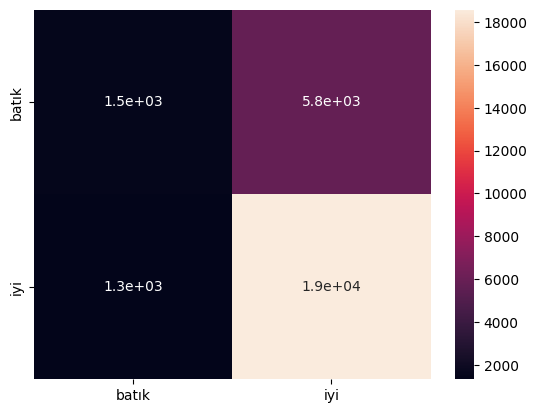

In [45]:
sns.heatmap(confusion_matrix(y_test,tahminler['RandomForest']), annot=True, xticklabels=['batık','iyi'], yticklabels=['batık','iyi']); # Random Forest, satırlar gerçek, sütunlar tahmin

**Sonuç:** Random Forest 19.907 iyi müşterinin 18.586'sını doğru tanıdı, ama 7.292 batık kredinin sadece 1.488'ini yakaladı; 5.804 batık krediye 'iyi müşteri' dedi. Model 0,5 eşiğiyle karar verdiğinde çok iyimser.

### İyi müşteriyi belirleme: olasılığa göre seçim

**Ne yapıyoruz:** Model her müşteri için bir 'krediyi ödeme olasılığı' veriyor. Banka bu olasılığa göre müşterileri sıralayıp en güvenli olanlara kredi verebilir. Derslerdeki `quantile` ile olasılığı en yüksek %50, %30 ve %10'luk müşteri gruplarını seçiyor ve bu gruplarda kredilerin gerçekte yüzde kaçının ödendiğine bakıyoruz.

In [46]:
secim=pd.DataFrame(index=olasiliklar.keys(), columns=['En_guvenli_yuzde_50','En_guvenli_yuzde_30','En_guvenli_yuzde_10']) # sonuç tablosu
for isim,o in olasiliklar.items(): # her model
    for oran,sutun in [(0.5,'En_guvenli_yuzde_50'),(0.7,'En_guvenli_yuzde_30'),(0.9,'En_guvenli_yuzde_10')]: # üç grup
        esik=np.quantile(o, oran) # olasılık eşiği
        secim.loc[isim,sutun]=y_test[o>=esik].mean() # seçilen gruptaki geri ödeme oranı
secim.astype(float).round(3) # gruplara göre geri ödeme oranı

,En_guvenli_yuzde_50,En_guvenli_yuzde_30,En_guvenli_yuzde_10
LogisticRegression,0.843,0.877,0.904
DecisionTree,0.839,0.875,0.919
RandomForest,0.843,0.879,0.918
KNN,0.791,0.791,0.825
GaussianNB,0.824,0.846,0.841


**Sonuç:** Bu tablo modellerin asıl değerini gösteriyor. Test verisinde bütün müşterilerin geri ödeme oranı %73,2. Random Forest'ın en güvenli bulduğu:
- %50'lik grupta geri ödeme oranı %84,3
- %30'luk grupta %87,9
- %10'luk grupta %91,8

Yani banka sadece modelin en güvenli bulduğu %30'luk gruba kredi verirse, batık kredi oranı %26,8'den %12,1'e iner; yarıdan fazla azalır. Random Forest, Logistic Regression ve Decision Tree bu konuda birbirine çok yakın; KNN ve Gaussian NB daha zayıf.

### Modelin en çok dikkat ettiği bilgiler

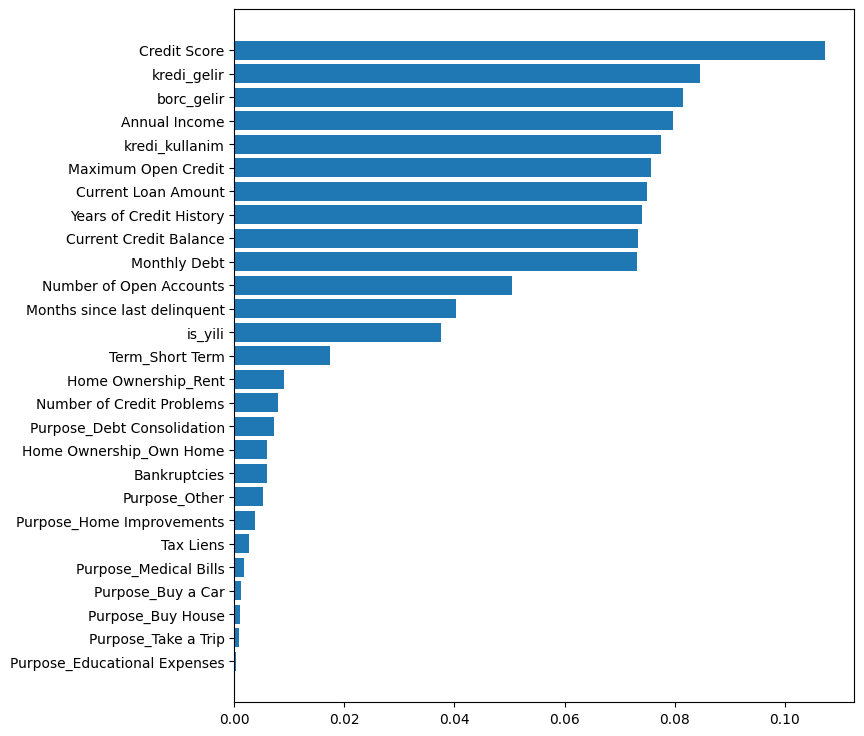

In [47]:
fi=pd.DataFrame({'Feature':x_train.columns, 'Importance':rf.feature_importances_}).sort_values('Importance') # Random Forest'ın özelliklere verdiği önem
plt.figure(figsize=(8,9)) # grafik boyutu
plt.barh(fi['Feature'],fi['Importance']); # yatay çubuk grafik

In [48]:
fi.sort_values('Importance', ascending=False).head(10) # en önemli 10 özellik

,Feature,Importance
1,Credit Score,0.107288
15,kredi_gelir,0.084582
14,borc_gelir,0.081434
2,Annual Income,0.079626
13,kredi_kullanim,0.077536
9,Maximum Open Credit,0.075674
0,Current Loan Amount,0.074966
4,Years of Credit History,0.074025
8,Current Credit Balance,0.073328
3,Monthly Debt,0.073156


**Sonuç:** Random Forest'a göre en önemli bilgi kredi notu. Sonra feature engineering ile oluşturduğumuz üç oran geliyor: kredi-gelir oranı, borç-gelir oranı ve kredi kullanım oranı. Bu üç oran, ham sütunlardan (gelir, kredi tutarı, aylık borç) daha önemli bulundu; yani feature engineering modele gerçekten faydalı bilgi kattı.

Önem değerleri birbirine çok yakın (0,07-0,11): tek bir bilgi kredinin kaderini belirlemiyor, risk birçok bilginin birleşiminden oluşuyor.

### Test verisinde iyi müşteri tahmini

**Ne yapıyoruz:** Ödevin istediği gibi eğitilmiş modelle test verisindeki müşterilerden kimin iyi müşteri olduğunu tahmin ediyoruz. Random Forest'ın verdiği olasılığa göre en güvenli %30'luk grubu 'iyi müşteri' olarak işaretliyoruz.

In [49]:
test_sonuc=x_test[['Credit Score','Annual Income','Current Loan Amount']].copy() # test müşterilerinin bazı bilgileri
test_sonuc['odeme_olasiligi']=olasiliklar['RandomForest'].round(3) # krediyi ödeme olasılığı
test_sonuc['iyi_musteri']=np.where(test_sonuc['odeme_olasiligi']>=np.quantile(olasiliklar['RandomForest'],0.7), 'evet', 'hayır') # en güvenli %30
test_sonuc['gercek']=np.where(y_test==1, 'ödedi', 'batık') # gerçek sonuç
test_sonuc.sort_values('odeme_olasiligi', ascending=False).head(10) # en güvenli 10 müşteri

,Credit Score,Annual Income,Current Loan Amount,odeme_olasiligi,iyi_musteri,gercek
91865,749.0,122913.0,8358.0,1.0,evet,ödedi
168034,749.0,124384.0,11557.0,1.0,evet,ödedi
164373,748.0,114285.0,14436.0,1.0,evet,ödedi
37612,750.0,83436.0,6871.0,1.0,evet,ödedi
158300,750.0,162129.0,23582.0,1.0,evet,ödedi
28572,750.0,50945.0,5095.0,1.0,evet,ödedi
26250,751.0,106827.0,10078.0,1.0,evet,ödedi
116318,750.0,35263.0,8060.0,1.0,evet,ödedi
67722,751.0,101541.0,5973.0,1.0,evet,ödedi
40585,751.0,143028.0,4932.0,1.0,evet,ödedi


In [50]:
test_sonuc.groupby('iyi_musteri')['gercek'].value_counts() # iyi müşteri grubunda ödeyen ve batan sayısı

iyi_musteri  gercek
evet         ödedi      7286
             batık      1006
hayır        ödedi     12621
             batık      6286
Name: count, dtype: int64

**Sonuç:** Model test verisindeki 27.199 müşterinin 8.292'sini (%30) 'iyi müşteri' olarak işaretledi. Bu müşterilerin 7.286'sı krediyi gerçekten ödedi (%87,9), 1.006'sı batırdı. 'İyi müşteri' denmeyen grupta ise batık oranı %33,2.

### Modeli kaydetme

In [51]:
import joblib # dosya kaydetme kütüphanesi
joblib.dump(rf,'kredi_model.pkl') # Random Forest modeli
joblib.dump(list(x_train.columns),'kredi_sutunlar.pkl') # modelin beklediği sütunlar

['kredi_sutunlar.pkl']

## Sonuçların Değerlendirilmesi

### Veri temizleme

Veri setinde ödevde belirtilen dört sorunun hepsi bulundu ve temizlendi:

| Sorun | Bulunan | Yapılan |
|---|---|---|
| Tekrar eden satırlar | 16.611 birebir tekrar, 24.673 kredi daha eksik değerle tekrar | `groupby('Loan ID').max()` ile her kredi tek satıra indirildi |
| Yazım farklılıkları | 'other'/'Other', 'HaveMortgage'/'Home Mortgage' | Tek yazıma çevrildi |
| Noktalama ve format | Monthly Debt'te '$' ve ',' ; Maximum Open Credit'te '#VALUE!' | Temizlenip sayıya çevrildi |
| Boş değerler | Kredi notu, gelir, iş yılı, geç ödeme, iflas, vergi haczi | Eğitim verisinin ortancasıyla dolduruldu; geç ödeme yoksa 200 ay |

Bunlara ek olarak, kredinin sonucuyla doğrudan bağlantılı üç **veri hatası** bulundu: 800'ün üzerinde yazılmış kredi notları (%100 batık), 99.999.999 yazılmış kredi tutarları (%100 ödenmiş) ve boş kredi notları (%5 batık). Bunlar düzeltilmeseydi modeller kredi riskini değil bu hataları ezberleyecek ve gerçek hayatta işe yaramayacaktı. Kredi notları düzeltildi, tutarı veya notu bilinmeyen krediler çıkarıldı. Sonuçta 135.992 kredi kaldı.

### Modeller

| Model | Tür | Accuracy | En güvenli %30'da geri ödeme |
|---|---|---|---|
| Logistic Regression | Regresyon tabanlı | 0.740 | 0.877 |
| Random Forest | Ağaç tabanlı | 0.738 | 0.879 |
| Decision Tree | Ağaç tabanlı | 0.735 | 0.875 |
| Gaussian NB | Olasılık tabanlı | 0.733 | 0.846 |
| KNN | Mesafe tabanlı | 0.702 | 0.791 |
| Herkese 'iyi müşteri' demek | - | 0.732 | 0.732 |

**Hedef accuracy > 0.80 idi; ulaşılamadı.** Veri hataları temizlendikten sonra en iyi model %74,0 accuracy aldı; bu, herkese 'krediyi öder' demekten sadece biraz daha iyi. Ödenen ve batan krediler bu verilerle birbirinden net ayrılamıyor. Veri hataları temizlenmeden yapılan bir denemede accuracy daha yüksek görünüyordu, ama o yüksek sonuç modelin veri hatalarını ezberlemesinden geliyordu.

**Banka için asıl sonuç:** Modelin değeri, herkesi doğru sınıflandırmasında değil, müşterileri riske göre sıralamasında. Random Forest'ın en güvenli bulduğu %30'luk müşteri grubunda geri ödeme oranı %87,9; bütün müşterilerde %73,2. Banka krediyi bu gruba verirse batık kredi oranı yarıdan fazla azalır. Kredi verilecek grubun büyüklüğü bankanın risk iştahına göre seçilebilir: daha küçük bir gruba (%10) kredi verilirse geri ödeme oranı %91,8'e çıkıyor.

Model `kredi_model.pkl`, modelin beklediği sütunlar `kredi_sutunlar.pkl` olarak kaydedildi.

## Kredi Başvurusunda Müşteriye Sorulacak Sorular

Modelin en önemli bulduğu bilgilere ve EDA bulgularına göre, kredi başvurusu sırasında müşteriden şu bilgiler mutlaka alınmalı ve doğrulanmalı:

1. **Kredi notunuz nedir? Kredi raporunuzu sorgulamamıza izin veriyor musunuz?** En önemli bilgi. Kredi notu bilinmeyen bir başvuru değerlendirilmemeli.
2. **Yıllık geliriniz nedir? Belgeleyebilir misiniz (maaş bordrosu, vergi beyannamesi)?** Gelir, en önemli üç oranın (kredi-gelir, borç-gelir) temelini oluşturuyor.
3. **Ne kadar kredi istiyorsunuz?** İstenen tutarın gelire oranı modelin en önemli ikinci bilgisi.
4. **Mevcut kredi ve kartlarınız için ayda toplam ne kadar ödüyorsunuz?** Borç-gelir oranını hesaplamak için.
5. **Kredi kartlarınızın toplam limiti ve şu anki toplam borcunuz nedir?** Kredi kullanım oranı için; limitinin çoğunu kullanan müşteri daha riskli.
6. **Krediyi hangi vadede almak istiyorsunuz?** Uzun vadeli kredilerde batık oranı (%34,5) kısa vadelilerin (%18) neredeyse iki katı.
7. **Krediyi ne için kullanacaksınız?** İş kredileri en riskli amaç (%34 batık); iş kredisi başvurularında iş planı istenmeli.
8. **Ne zamandır kredi kullanıyorsunuz? Son yıllarda geç ödemeniz, iflasınız veya vergi haczi oldu mu?** Kredi geçmişinin uzunluğu modelde önemli; geçmiş sorunlar riski artırıyor.
9. **Evinizin durumu nedir (kira, ipotekli, kendi eviniz)?** Kirada oturanlarda batık oranı ev sahiplerinden daha yüksek.

## Kodun Değerlendirilmesi

Ödevin istediği adımlar izlendi: EDA, veri temizleme, eğitim-test bölmesi, boş değerlerin doldurulması, kategorik verilerin sayıya çevrilmesi, feature engineering, 4 algoritma türünden 5 model, değerlendirme ve test verisinde iyi müşteri tahmini. Derslerdeki yöntemler kullanıldı: groupby, np.where, str.replace, fillna, get_dummies, StandardScaler, 5 sınıflandırma modeli, predict_proba, quantile, feature_importances_ ve joblib. Boş değerlerin doldurma değerleri ve scaler sadece eğitim verisinden öğrenildi.

## Eksikler ve Sınırlılıklar

- Veri setinde kredinin sonucuyla bağlantılı veri hataları var; bu hatalı kayıtlar (yaklaşık 80 bin kredi) çıkarıldı. Bu kredilerin gerçek değerleri bilinseydi model daha fazla veriyle eğitilebilirdi.
- EDA bölümündeki vade, ev sahipliği ve amaç oranları, kredi notu boş olanlar çıkarılmadan önceki veriyle hesaplandı.
- Bir müşterinin birden fazla kredisi olabiliyor; aynı müşterinin kredileri hem eğitimde hem testte bulunabilir.
- Modeller varsayılan 0,5 eşiğiyle çok iyimser; banka kendi risk iştahına göre farklı bir eşik veya grup büyüklüğü seçmeli.
- KNN, eğitim verisi büyük olduğu için yavaş çalışıyor (birkaç dakika).